In [1]:
# ============================================================
# CELL 1: FINAL YOLO DATASET PREPARATION - SETUP
# ============================================================

from pathlib import Path
import os
import json
import random
import shutil
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = Path(r"E:\SmartVision-AI\data\final_dataset")

CLASSIFICATION_DIR = BASE_DIR / "classification"
DETECTION_DIR = BASE_DIR / "detection"

IMAGES_DIR = DETECTION_DIR / "images"
LABELS_DIR = DETECTION_DIR / "labels"

# ------------------------------------------------------------
# Final 25 classes
# Original COCO category IDs
# ------------------------------------------------------------

SELECTED_CLASSES = {
    "person": 0,
    "bicycle": 1,
    "car": 2,
    "motorcycle": 3,
    "airplane": 4,
    "bus": 5,
    "train": 6,
    "truck": 7,
    "traffic light": 9,
    "stop sign": 11,
    "bench": 13,
    "bird": 14,
    "cat": 15,
    "dog": 16,
    "horse": 17,
    "cow": 19,
    "elephant": 20,
    "bottle": 39,
    "cup": 41,
    "bowl": 45,
    "pizza": 53,
    "cake": 55,
    "chair": 56,
    "potted plant": 58,
    "bed": 59
}

# ------------------------------------------------------------
# YOLO requires contiguous IDs: 0 ... 24
# ------------------------------------------------------------

CLASS_NAMES = list(SELECTED_CLASSES.keys())

COCO_TO_YOLO = {
    coco_id: yolo_id
    for yolo_id, coco_id in enumerate(SELECTED_CLASSES.values())
}

YOLO_TO_CLASS = {
    yolo_id: class_name
    for yolo_id, class_name in enumerate(CLASS_NAMES)
}

# ------------------------------------------------------------
# Create folder structure
# ------------------------------------------------------------

for split in ["train", "val", "test"]:

    (IMAGES_DIR / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (LABELS_DIR / split).mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 72)
print("SMARTVISION AI - FINAL YOLO DATASET SETUP")
print("=" * 72)

print("\nBase directory:")
print(BASE_DIR)

print("\nDetection directory:")
print(DETECTION_DIR)

print("\nNumber of classes:", len(CLASS_NAMES))

print("\nCOCO ID -> YOLO ID -> Class")
print("-" * 45)

for class_name, coco_id in SELECTED_CLASSES.items():

    yolo_id = COCO_TO_YOLO[coco_id]

    print(
        f"COCO {coco_id:2d}  ->  "
        f"YOLO {yolo_id:2d}  ->  "
        f"{class_name}"
    )

print("\nFolder verification:")

for split in ["train", "val", "test"]:

    print(
        f"{split:5s} | "
        f"images: {(IMAGES_DIR / split).exists()} | "
        f"labels: {(LABELS_DIR / split).exists()}"
    )

print("\n" + "=" * 72)
print("✅ Final YOLO folder structure created.")
print("✅ 25-class contiguous YOLO mapping created.")
print("=" * 72)

SMARTVISION AI - FINAL YOLO DATASET SETUP

Base directory:
E:\SmartVision-AI\data\final_dataset

Detection directory:
E:\SmartVision-AI\data\final_dataset\detection

Number of classes: 25

COCO ID -> YOLO ID -> Class
---------------------------------------------
COCO  0  ->  YOLO  0  ->  person
COCO  1  ->  YOLO  1  ->  bicycle
COCO  2  ->  YOLO  2  ->  car
COCO  3  ->  YOLO  3  ->  motorcycle
COCO  4  ->  YOLO  4  ->  airplane
COCO  5  ->  YOLO  5  ->  bus
COCO  6  ->  YOLO  6  ->  train
COCO  7  ->  YOLO  7  ->  truck
COCO  9  ->  YOLO  8  ->  traffic light
COCO 11  ->  YOLO  9  ->  stop sign
COCO 13  ->  YOLO 10  ->  bench
COCO 14  ->  YOLO 11  ->  bird
COCO 15  ->  YOLO 12  ->  cat
COCO 16  ->  YOLO 13  ->  dog
COCO 17  ->  YOLO 14  ->  horse
COCO 19  ->  YOLO 15  ->  cow
COCO 20  ->  YOLO 16  ->  elephant
COCO 39  ->  YOLO 17  ->  bottle
COCO 41  ->  YOLO 18  ->  cup
COCO 45  ->  YOLO 19  ->  bowl
COCO 53  ->  YOLO 20  ->  pizza
COCO 55  ->  YOLO 21  ->  cake
COCO 56  ->  YOLO 22 

In [2]:
# ============================================================
# CELL 2: RECOVER SOURCE-IMAGE SPLITS
# ============================================================

CLASSIFICATION_DIR = BASE_DIR / "classification"


def extract_source_idx(filepath):
    """
    Classification filename format:
    class_sourceidx_itemindex.jpg

    Example:
    airplane_000016_065.jpg
                 ^^^^^^
              source_idx
    """
    return int(filepath.stem.split("_")[-2])


source_splits = {}

for split in ["train", "val", "test"]:

    split_dir = CLASSIFICATION_DIR / split

    source_ids = set()

    for class_dir in split_dir.iterdir():

        if not class_dir.is_dir():
            continue

        for image_path in class_dir.glob("*.jpg"):
            source_ids.add(extract_source_idx(image_path))

    source_splits[split] = source_ids


# ------------------------------------------------------------
# Extract sets
# ------------------------------------------------------------

train_sources = source_splits["train"]
val_sources   = source_splits["val"]
test_sources  = source_splits["test"]


# ------------------------------------------------------------
# Leakage checks
# ------------------------------------------------------------

train_val_overlap  = train_sources & val_sources
train_test_overlap = train_sources & test_sources
val_test_overlap   = val_sources & test_sources


print("=" * 72)
print("SOURCE-IMAGE SPLIT RECOVERY")
print("=" * 72)

print("\nUnique source images:")
print("Train :", len(train_sources))
print("Val   :", len(val_sources))
print("Test  :", len(test_sources))

print("\nTotal unique source images:")
print(
    len(
        train_sources |
        val_sources |
        test_sources
    )
)

print("\nSource-image leakage:")
print("Train ↔ Val  :", len(train_val_overlap))
print("Train ↔ Test :", len(train_test_overlap))
print("Val ↔ Test   :", len(val_test_overlap))


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

assert len(
    train_sources |
    val_sources |
    test_sources
) == 1989


print("\nExample source IDs:")

print("Train :", sorted(train_sources)[:10])
print("Val   :", sorted(val_sources)[:10])
print("Test  :", sorted(test_sources)[:10])

print("\n" + "=" * 72)
print("✅ Source-image splits recovered successfully.")
print("✅ No source image appears in multiple splits.")
print("=" * 72)

SOURCE-IMAGE SPLIT RECOVERY

Unique source images:
Train : 1410
Val   : 283
Test  : 296

Total unique source images:
1989

Source-image leakage:
Train ↔ Val  : 0
Train ↔ Test : 0
Val ↔ Test   : 0

Example source IDs:
Train : [3, 5, 6, 9, 12, 16, 17, 22, 23, 24]
Val   : [13, 36, 56, 59, 69, 70, 76, 77, 78, 82]
Test  : [1, 19, 42, 92, 93, 101, 107, 109, 134, 137]

✅ Source-image splits recovered successfully.
✅ No source image appears in multiple splits.


In [3]:
# ============================================================
# CELL 3: LOAD COCO STREAM FOR DETECTION DATASET
# ============================================================

from datasets import load_dataset

print("=" * 72)
print("LOADING COCO STREAM")
print("=" * 72)

dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

print("\nDataset type:")
print(type(dataset))

print("\nDataset features:")
print(dataset.features)

print("\n" + "=" * 72)
print("✅ COCO streaming dataset loaded successfully.")
print("=" * 72)

LOADING COCO STREAM


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]


Dataset type:
<class 'datasets.iterable_dataset.IterableDataset'>

Dataset features:
{'image_id': Value('int64'), 'image': Image(mode=None, decode=True), 'width': Value('int64'), 'height': Value('int64'), 'objects': {'bbox_id': List(Value('int64')), 'category': List(ClassLabel(names=['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'c

In [4]:
# ============================================================
# CELL 4: INSPECT RAW COCO ANNOTATIONS
# ============================================================

# Use a few source IDs from our final dataset
sample_source_ids = sorted(
    list(train_sources | val_sources | test_sources)
)[:3]

sample_source_ids = set(sample_source_ids)

print("=" * 72)
print("RAW COCO ANNOTATION INSPECTION")
print("=" * 72)

found = 0

for source_idx, item in enumerate(dataset):

    if source_idx not in sample_source_ids:
        continue

    image = item["image"]
    objects = item["objects"]

    print(f"\nSOURCE INDEX : {source_idx}")
    print(f"IMAGE ID     : {item['image_id']}")
    print(f"IMAGE SIZE   : {item['width']} × {item['height']}")
    print(f"IMAGE MODE   : {image.mode}")

    print("\nObject annotation keys:")
    print(objects.keys())

    print("\nNumber of objects:", len(objects["category"]))

    print("\nFirst few annotations:")
    print("-" * 72)

    for i in range(min(5, len(objects["category"]))):

        category_id = objects["category"][i]
        bbox = objects["bbox"][i]
        area = objects["area"][i]

        # Interpret bbox as XYXY
        x1, y1, x2, y2 = bbox

        calculated_width = x2 - x1
        calculated_height = y2 - y1
        calculated_area = calculated_width * calculated_height

        class_name = dataset.features["objects"]["category"].feature.int2str(
            category_id
        )

        print(f"\nObject {i + 1}")
        print("Class ID        :", category_id)
        print("Class name      :", class_name)
        print("Raw bbox        :", bbox)
        print(
            "XYXY size       :",
            f"{calculated_width:.2f} × {calculated_height:.2f}"
        )
        print("Stored area     :", round(area, 2))
        print("XYXY bbox area  :", round(calculated_area, 2))

    found += 1

    if found == len(sample_source_ids):
        break


print("\n" + "=" * 72)
print(f"Inspected {found} selected source images.")
print("=" * 72)

RAW COCO ANNOTATION INSPECTION

SOURCE INDEX : 1
IMAGE ID     : 25
IMAGE SIZE   : 640 × 426
IMAGE MODE   : RGB

Object annotation keys:
dict_keys(['bbox_id', 'category', 'bbox', 'area'])

Number of objects: 2

First few annotations:
------------------------------------------------------------------------

Object 1
Class ID        : 23
Class name      : giraffe
Raw bbox        : [385.53, 60.03, 600.5, 357.19000000000005]
XYXY size       : 214.97 × 297.16
Stored area     : 19686.6
XYXY bbox area  : 63880.49

Object 2
Class ID        : 23
Class name      : giraffe
Raw bbox        : [53.01, 356.49, 185.04, 411.68]
XYXY size       : 132.03 × 55.19
Stored area     : 2785.85
XYXY bbox area  : 7286.74

SOURCE INDEX : 3
IMAGE ID     : 34
IMAGE SIZE   : 640 × 425
IMAGE MODE   : RGB

Object annotation keys:
dict_keys(['bbox_id', 'category', 'bbox', 'area'])

Number of objects: 1

First few annotations:
------------------------------------------------------------------------

Object 1
Class ID    

In [5]:
# ============================================================
# CELL 5: LOW-MEMORY DETECTION PREPARATION
# ============================================================

import gc

# Remove any old large object if it exists
if "detection_records" in globals():
    del detection_records

gc.collect()

# All source images required for final detection dataset
required_sources = (
    train_sources |
    val_sources |
    test_sources
)

max_required_idx = max(required_sources)

print("=" * 72)
print("LOW-MEMORY DETECTION PREPARATION")
print("=" * 72)

print("Required source images :", len(required_sources))
print("Maximum source index  :", max_required_idx)

print("\nSplit requirements:")
print("Train :", len(train_sources))
print("Val   :", len(val_sources))
print("Test  :", len(test_sources))

print("\nMemory strategy:")
print("• Do NOT keep original images in a Python dictionary")
print("• Process one required source image at a time")
print("• Save image directly to disk")
print("• Save YOLO annotation directly to disk")
print("• Release image before continuing")

print("\n" + "=" * 72)
print("✅ Ready for low-memory YOLO generation.")
print("=" * 72)

LOW-MEMORY DETECTION PREPARATION
Required source images : 1989
Maximum source index  : 24236

Split requirements:
Train : 1410
Val   : 283
Test  : 296

Memory strategy:
• Do NOT keep original images in a Python dictionary
• Process one required source image at a time
• Save image directly to disk
• Save YOLO annotation directly to disk
• Release image before continuing

✅ Ready for low-memory YOLO generation.


In [6]:
# ============================================================
# CELL 6: GENERATE FINAL YOLO DATASET - LOW MEMORY
# ============================================================

import gc

saved_images = 0
saved_labels = 0
saved_objects = 0

split_image_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

split_object_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}


print("=" * 72)
print("GENERATING FINAL YOLO DATASET")
print("=" * 72)


for source_idx, item in enumerate(dataset):

    # Stop once we pass the highest required source index
    if source_idx > max_required_idx:
        break

    # Ignore images not used in our final dataset
    if source_idx not in required_sources:
        continue

    # --------------------------------------------------------
    # Determine split
    # --------------------------------------------------------

    if source_idx in train_sources:
        split = "train"

    elif source_idx in val_sources:
        split = "val"

    else:
        split = "test"

    # --------------------------------------------------------
    # Image information
    # --------------------------------------------------------

    image = item["image"]

    if image.mode != "RGB":
        image = image.convert("RGB")

    img_width = item["width"]
    img_height = item["height"]

    objects = item["objects"]

    # --------------------------------------------------------
    # Convert selected annotations to YOLO format
    # --------------------------------------------------------

    yolo_lines = []

    for category_id, bbox in zip(
        objects["category"],
        objects["bbox"]
    ):

        # Ignore classes outside our final 25
        if category_id not in COCO_TO_YOLO:
            continue

        # Correct HF COCO format: XYXY
        x1, y1, x2, y2 = bbox

        # Clip bbox to image boundaries
        x1 = max(0.0, min(float(x1), img_width))
        y1 = max(0.0, min(float(y1), img_height))
        x2 = max(0.0, min(float(x2), img_width))
        y2 = max(0.0, min(float(y2), img_height))

        bbox_width = x2 - x1
        bbox_height = y2 - y1

        # Skip invalid boxes
        if bbox_width <= 0 or bbox_height <= 0:
            continue

        # ----------------------------------------------------
        # XYXY -> normalized YOLO
        # ----------------------------------------------------

        x_center = ((x1 + x2) / 2.0) / img_width
        y_center = ((y1 + y2) / 2.0) / img_height

        norm_width = bbox_width / img_width
        norm_height = bbox_height / img_height

        yolo_id = COCO_TO_YOLO[category_id]

        yolo_lines.append(
            f"{yolo_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{norm_width:.6f} "
            f"{norm_height:.6f}"
        )

    # --------------------------------------------------------
    # Important:
    # only save images containing at least one of our 25 classes
    # --------------------------------------------------------

    if len(yolo_lines) == 0:
        del image
        continue

    # --------------------------------------------------------
    # Output filenames
    # --------------------------------------------------------

    image_filename = f"coco_{source_idx:06d}.jpg"
    label_filename = f"coco_{source_idx:06d}.txt"

    image_path = IMAGES_DIR / split / image_filename
    label_path = LABELS_DIR / split / label_filename

    # --------------------------------------------------------
    # Save original image
    # --------------------------------------------------------

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    # --------------------------------------------------------
    # Save YOLO annotation
    # --------------------------------------------------------

    with open(label_path, "w", encoding="utf-8") as f:
        f.write("\n".join(yolo_lines))

    # --------------------------------------------------------
    # Update counters
    # --------------------------------------------------------

    saved_images += 1
    saved_labels += 1
    saved_objects += len(yolo_lines)

    split_image_counts[split] += 1
    split_object_counts[split] += len(yolo_lines)

    # Release image immediately
    del image

    # Occasional garbage collection
    if saved_images % 100 == 0:

        gc.collect()

        print(
            f"Saved {saved_images:4d} images | "
            f"{saved_objects:5d} objects"
        )


# Final cleanup
gc.collect()


print("\n" + "=" * 72)
print("YOLO DATASET GENERATION SUMMARY")
print("=" * 72)

print("\nImages:")
print("Train :", split_image_counts["train"])
print("Val   :", split_image_counts["val"])
print("Test  :", split_image_counts["test"])
print("Total :", saved_images)

print("\nObjects:")
print("Train :", split_object_counts["train"])
print("Val   :", split_object_counts["val"])
print("Test  :", split_object_counts["test"])
print("Total :", saved_objects)

print("\nLabel files :", saved_labels)

print("\n" + "=" * 72)
print("✅ Low-memory YOLO generation completed.")
print("=" * 72)

GENERATING FINAL YOLO DATASET
Saved  100 images |   511 objects
Saved  200 images |  1065 objects
Saved  300 images |  1604 objects
Saved  400 images |  2163 objects
Saved  500 images |  2621 objects
Saved  600 images |  3157 objects
Saved  700 images |  3688 objects
Saved  800 images |  4295 objects
Saved  900 images |  4764 objects
Saved 1000 images |  5297 objects
Saved 1100 images |  5775 objects
Saved 1200 images |  6218 objects
Saved 1300 images |  6671 objects
Saved 1400 images |  7140 objects
Saved 1500 images |  7661 objects
Saved 1600 images |  8166 objects

YOLO DATASET GENERATION SUMMARY

Images:
Train : 1200
Val   : 244
Test  : 240
Total : 1684

Objects:
Train : 6144
Val   : 1208
Test  : 1260
Total : 8612

Label files : 1684

✅ Low-memory YOLO generation completed.


In [7]:
# ============================================================
# CELL 7: VERIFY SOURCE_IDX ALIGNMENT
# ============================================================

from pathlib import Path
import re

CLASSIFICATION_DIR = BASE_DIR / "classification"

# Check a few source IDs we already inspected
check_ids = [1, 3, 5]

print("=" * 72)
print("SOURCE INDEX ALIGNMENT CHECK")
print("=" * 72)

for sid in check_ids:

    references = []

    for split in ["train", "val", "test"]:

        split_dir = CLASSIFICATION_DIR / split

        for class_dir in split_dir.iterdir():

            if not class_dir.is_dir():
                continue

            for img_path in class_dir.glob("*.jpg"):

                # Filename format:
                # class_name_000001_XXX.jpg

                match = re.search(r"_(\d{6})_\d+\.jpg$", img_path.name)

                if match and int(match.group(1)) == sid:
                    references.append(
                        (split, class_dir.name, img_path.name)
                    )

    print(f"\nSource index: {sid}")

    if references:
        print("Classification dataset says:")

        for ref in references:
            print(
                f"  Split={ref[0]:5s} | "
                f"Class={ref[1]:15s} | "
                f"{ref[2]}"
            )
    else:
        print("  No classification reference found.")

print("\n" + "=" * 72)

SOURCE INDEX ALIGNMENT CHECK

Source index: 1
Classification dataset says:
  Split=test  | Class=bowl            | bowl_000001_002.jpg
  Split=test  | Class=bowl            | bowl_000001_003.jpg
  Split=test  | Class=bowl            | bowl_000001_004.jpg

Source index: 3
Classification dataset says:
  Split=train | Class=potted plant    | potted_plant_000003_023.jpg

Source index: 5
Classification dataset says:
  Split=train | Class=person          | person_000005_062.jpg



In [8]:
# ============================================================
# CELL 8: CLEAR INCORRECT DETECTION OUTPUT
# ============================================================

print("=" * 72)
print("CLEARING INCORRECT DETECTION OUTPUT")
print("=" * 72)

for split in ["train", "val", "test"]:

    image_dir = IMAGES_DIR / split
    label_dir = LABELS_DIR / split

    # Delete generated detection images
    for file in image_dir.glob("*"):
        if file.is_file():
            file.unlink()

    # Delete generated YOLO labels
    for file in label_dir.glob("*"):
        if file.is_file():
            file.unlink()

    print(f"Cleared: {split}")

print("\nRemaining files:")

for split in ["train", "val", "test"]:

    image_count = len(list((IMAGES_DIR / split).glob("*")))
    label_count = len(list((LABELS_DIR / split).glob("*")))

    print(
        f"{split:5s} | "
        f"images={image_count:4d} | "
        f"labels={label_count:4d}"
    )

print("\n" + "=" * 72)
print("✅ Incorrect detection output removed.")
print("✅ Classification dataset was NOT touched.")
print("=" * 72)

CLEARING INCORRECT DETECTION OUTPUT
Cleared: train
Cleared: val
Cleared: test

Remaining files:
train | images=   0 | labels=   0
val   | images=   0 | labels=   0
test  | images=   0 | labels=   0

✅ Incorrect detection output removed.
✅ Classification dataset was NOT touched.


In [9]:
# ============================================================
# CELL 9: COUNT SELECTED CLASSES IN CURRENT COCO STREAM
# ============================================================

from collections import Counter
import gc

class_counts = Counter()

# Reverse mapping:
# COCO category ID -> class name
COCO_ID_TO_NAME = {
    coco_id: class_name
    for class_name, coco_id in SELECTED_CLASSES.items()
}

TARGET_PER_CLASS = 100

processed_images = 0

print("=" * 72)
print("SCANNING COCO FOR SELECTED CLASSES")
print("=" * 72)

# Fresh stream
scan_dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

for item in scan_dataset:

    processed_images += 1

    # Count each class at most once per source image
    categories_in_image = set(item["objects"]["category"])

    for category_id in categories_in_image:

        if category_id in COCO_ID_TO_NAME:
            class_name = COCO_ID_TO_NAME[category_id]

            if class_counts[class_name] < TARGET_PER_CLASS:
                class_counts[class_name] += 1

    # Check whether every class has reached 100 images
    if all(
        class_counts[class_name] >= TARGET_PER_CLASS
        for class_name in SELECTED_CLASSES
    ):
        break

    if processed_images % 2000 == 0:
        completed = sum(
            class_counts[c] >= TARGET_PER_CLASS
            for c in SELECTED_CLASSES
        )

        print(
            f"Processed {processed_images:5d} images | "
            f"Classes reaching 100: {completed}/25"
        )

gc.collect()

print("\n" + "=" * 72)
print("SCAN SUMMARY")
print("=" * 72)

print("Images scanned:", processed_images)

print("\nClass image counts:")

for class_name in SELECTED_CLASSES:
    print(
        f"{class_name:15s}: "
        f"{class_counts[class_name]:3d}"
    )

completed = sum(
    class_counts[c] >= TARGET_PER_CLASS
    for c in SELECTED_CLASSES
)

print("\nClasses reaching target:", completed, "/ 25")

print("=" * 72)

SCANNING COCO FOR SELECTED CLASSES


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Processed  2000 images | Classes reaching 100: 7/25
Processed  4000 images | Classes reaching 100: 20/25
Processed  6000 images | Classes reaching 100: 23/25

SCAN SUMMARY
Images scanned: 6895

Class image counts:
person         : 100
bicycle        : 100
car            : 100
motorcycle     : 100
airplane       : 100
bus            : 100
train          : 100
truck          : 100
traffic light  : 100
stop sign      : 100
bench          : 100
bird           : 100
cat            : 100
dog            : 100
horse          : 100
cow            : 100
elephant       : 100
bottle         : 100
cup            : 100
bowl           : 100
pizza          : 100
cake           : 100
chair          : 100
potted plant   : 100
bed            : 100

Classes reaching target: 25 / 25


In [10]:
# ============================================================
# CELL 10: SELECT DETECTION SOURCE IMAGES
# ============================================================

from collections import defaultdict
import gc

TARGET_PER_CLASS = 100

# Stores only integer stream positions — NOT images
selected_for_class = {
    class_name: []
    for class_name in SELECTED_CLASSES
}

# source_idx -> classes for which this image was selected
selected_sources = defaultdict(list)

print("=" * 72)
print("SELECTING DETECTION SOURCE IMAGES")
print("=" * 72)

selection_dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

processed = 0

for source_idx, item in enumerate(selection_dataset):

    processed += 1

    categories_in_image = set(item["objects"]["category"])

    for category_id in categories_in_image:

        if category_id not in COCO_ID_TO_NAME:
            continue

        class_name = COCO_ID_TO_NAME[category_id]

        # This class already has its required 100 images
        if len(selected_for_class[class_name]) >= TARGET_PER_CLASS:
            continue

        selected_for_class[class_name].append(source_idx)
        selected_sources[source_idx].append(class_name)

    # Stop once every class has 100 images
    if all(
        len(selected_for_class[class_name]) >= TARGET_PER_CLASS
        for class_name in SELECTED_CLASSES
    ):
        break

gc.collect()

print("\nImages scanned:", processed)

print("\nSelected assignments per class:")

for class_name in SELECTED_CLASSES:
    print(
        f"{class_name:15s}: "
        f"{len(selected_for_class[class_name]):3d}"
    )

total_assignments = sum(
    len(v) for v in selected_for_class.values()
)

unique_sources = len(selected_sources)

multi_class_sources = sum(
    len(classes) > 1
    for classes in selected_sources.values()
)

print("\n" + "=" * 72)

print("Total class assignments :", total_assignments)
print("Unique source images    :", unique_sources)
print("Multi-class sources     :", multi_class_sources)

print("=" * 72)

SELECTING DETECTION SOURCE IMAGES


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]


Images scanned: 6895

Selected assignments per class:
person         : 100
bicycle        : 100
car            : 100
motorcycle     : 100
airplane       : 100
bus            : 100
train          : 100
truck          : 100
traffic light  : 100
stop sign      : 100
bench          : 100
bird           : 100
cat            : 100
dog            : 100
horse          : 100
cow            : 100
elephant       : 100
bottle         : 100
cup            : 100
bowl           : 100
pizza          : 100
cake           : 100
chair          : 100
potted plant   : 100
bed            : 100

Total class assignments : 2500
Unique source images    : 1817
Multi-class sources     : 493


In [11]:
# ============================================================
# CELL 11: CREATE LEAKAGE-FREE 70/15/15 DETECTION SPLIT
# ============================================================

import random
from collections import Counter

random.seed(42)

SPLIT_RATIOS = {
    "train": 0.70,
    "val":   0.15,
    "test":  0.15
}

source_ids = list(selected_sources.keys())
random.shuffle(source_ids)

# Put multi-class images first because they are harder to place
source_ids.sort(
    key=lambda sid: len(selected_sources[sid]),
    reverse=True
)

# Desired number of class assignments per split
target_class_counts = {
    "train": {
        cls: 70 for cls in SELECTED_CLASSES
    },
    "val": {
        cls: 15 for cls in SELECTED_CLASSES
    },
    "test": {
        cls: 15 for cls in SELECTED_CLASSES
    }
}

split_sources = {
    "train": set(),
    "val": set(),
    "test": set()
}

split_class_counts = {
    "train": Counter(),
    "val": Counter(),
    "test": Counter()
}


# ------------------------------------------------------------
# Greedy multilabel assignment
# ------------------------------------------------------------

for sid in source_ids:

    classes = selected_sources[sid]

    best_split = None
    best_score = None

    for split in ["train", "val", "test"]:

        # How much this source helps classes that still need images
        need_score = sum(
            max(
                target_class_counts[split][cls]
                - split_class_counts[split][cls],
                0
            )
            for cls in classes
        )

        # Penalize exceeding class targets
        overflow = sum(
            max(
                split_class_counts[split][cls] + 1
                - target_class_counts[split][cls],
                0
            )
            for cls in classes
        )

        score = need_score - (overflow * 100)

        if best_score is None or score > best_score:
            best_score = score
            best_split = split

    split_sources[best_split].add(sid)

    for cls in classes:
        split_class_counts[best_split][cls] += 1


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 72)
print("DETECTION SPLIT SUMMARY")
print("=" * 72)

for split in ["train", "val", "test"]:

    print(
        f"{split:5s} | "
        f"unique images = {len(split_sources[split]):4d} | "
        f"class assignments = {sum(split_class_counts[split].values()):4d}"
    )


print("\nLeakage check:")

print(
    "Train ↔ Val :",
    len(split_sources["train"] & split_sources["val"])
)

print(
    "Train ↔ Test:",
    len(split_sources["train"] & split_sources["test"])
)

print(
    "Val ↔ Test  :",
    len(split_sources["val"] & split_sources["test"])
)


print("\nPer-class split counts:")
print("-" * 72)

for cls in SELECTED_CLASSES:

    tr = split_class_counts["train"][cls]
    va = split_class_counts["val"][cls]
    te = split_class_counts["test"][cls]

    print(
        f"{cls:15s} | "
        f"Train {tr:3d} | "
        f"Val {va:3d} | "
        f"Test {te:3d} | "
        f"Total {tr + va + te:3d}"
    )

print("=" * 72)

DETECTION SPLIT SUMMARY
train | unique images = 1108 | class assignments = 1750
val   | unique images =  353 | class assignments =  375
test  | unique images =  356 | class assignments =  375

Leakage check:
Train ↔ Val : 0
Train ↔ Test: 0
Val ↔ Test  : 0

Per-class split counts:
------------------------------------------------------------------------
person          | Train  70 | Val  15 | Test  15 | Total 100
bicycle         | Train  70 | Val  15 | Test  15 | Total 100
car             | Train  70 | Val  15 | Test  15 | Total 100
motorcycle      | Train  70 | Val  15 | Test  15 | Total 100
airplane        | Train  70 | Val  15 | Test  15 | Total 100
bus             | Train  70 | Val  15 | Test  15 | Total 100
train           | Train  70 | Val  15 | Test  15 | Total 100
truck           | Train  70 | Val  15 | Test  15 | Total 100
traffic light   | Train  70 | Val  15 | Test  15 | Total 100
stop sign       | Train  70 | Val  15 | Test  15 | Total 100
bench           | Train  70 | Val  1

In [12]:
# ============================================================
# CELL 12: GENERATE FINAL YOLO DETECTION DATASET
# ============================================================

import gc

all_detection_sources = (
    split_sources["train"] |
    split_sources["val"] |
    split_sources["test"]
)

max_detection_idx = max(all_detection_sources)

saved_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

object_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

print("=" * 72)
print("GENERATING FINAL YOLO DETECTION DATASET")
print("=" * 72)

print("Unique source images:", len(all_detection_sources))
print("Maximum stream index:", max_detection_idx)

# Fresh stream
generation_dataset = load_dataset(
    "detection-datasets/coco",
    split="train",
    streaming=True
)

for source_idx, item in enumerate(generation_dataset):

    if source_idx > max_detection_idx:
        break

    if source_idx not in all_detection_sources:
        continue

    # --------------------------------------------------------
    # Determine split
    # --------------------------------------------------------

    if source_idx in split_sources["train"]:
        split = "train"

    elif source_idx in split_sources["val"]:
        split = "val"

    else:
        split = "test"

    image = item["image"]

    if image.mode != "RGB":
        image = image.convert("RGB")

    width = item["width"]
    height = item["height"]

    objects = item["objects"]

    yolo_lines = []

    # --------------------------------------------------------
    # Convert ALL annotations belonging to our selected classes
    # --------------------------------------------------------

    for category_id, bbox in zip(
        objects["category"],
        objects["bbox"]
    ):

        if category_id not in COCO_TO_YOLO:
            continue

        # HF COCO bbox = XYXY
        x1, y1, x2, y2 = map(float, bbox)

        # Clip to image boundaries
        x1 = max(0.0, min(x1, width))
        y1 = max(0.0, min(y1, height))
        x2 = max(0.0, min(x2, width))
        y2 = max(0.0, min(y2, height))

        box_w = x2 - x1
        box_h = y2 - y1

        if box_w <= 0 or box_h <= 0:
            continue

        # XYXY -> normalized YOLO
        x_center = ((x1 + x2) / 2.0) / width
        y_center = ((y1 + y2) / 2.0) / height

        norm_w = box_w / width
        norm_h = box_h / height

        yolo_class = COCO_TO_YOLO[category_id]

        yolo_lines.append(
            f"{yolo_class} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{norm_w:.6f} "
            f"{norm_h:.6f}"
        )

    # Every selected source should contain at least one
    # selected-class annotation.
    if not yolo_lines:
        print(
            f"WARNING: source {source_idx} "
            "contains no selected annotations."
        )
        del image
        continue

    # --------------------------------------------------------
    # Save image and label
    # --------------------------------------------------------

    image_name = f"coco_{source_idx:06d}.jpg"
    label_name = f"coco_{source_idx:06d}.txt"

    image_path = IMAGES_DIR / split / image_name
    label_path = LABELS_DIR / split / label_name

    image.save(
        image_path,
        format="JPEG",
        quality=95
    )

    with open(label_path, "w", encoding="utf-8") as f:
        f.write("\n".join(yolo_lines))

    saved_counts[split] += 1
    object_counts[split] += len(yolo_lines)

    del image

    total_saved = sum(saved_counts.values())

    if total_saved % 100 == 0:
        gc.collect()

        print(
            f"Saved {total_saved:4d} / "
            f"{len(all_detection_sources)} images"
        )

gc.collect()

print("\n" + "=" * 72)
print("FINAL YOLO GENERATION SUMMARY")
print("=" * 72)

for split in ["train", "val", "test"]:

    print(
        f"{split:5s} | "
        f"images = {saved_counts[split]:4d} | "
        f"objects = {object_counts[split]:5d}"
    )

print("-" * 72)

print(
    "Total images :",
    sum(saved_counts.values())
)

print(
    "Total objects:",
    sum(object_counts.values())
)

print("=" * 72)
print("✅ Final YOLO detection dataset generated.")
print("=" * 72)

GENERATING FINAL YOLO DETECTION DATASET
Unique source images: 1817
Maximum stream index: 6894


Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Saved  100 / 1817 images
Saved  200 / 1817 images
Saved  300 / 1817 images
Saved  400 / 1817 images
Saved  500 / 1817 images
Saved  600 / 1817 images
Saved  700 / 1817 images
Saved  800 / 1817 images
Saved  900 / 1817 images
Saved 1000 / 1817 images
Saved 1100 / 1817 images
Saved 1200 / 1817 images
Saved 1300 / 1817 images
Saved 1400 / 1817 images
Saved 1500 / 1817 images
Saved 1600 / 1817 images
Saved 1700 / 1817 images
Saved 1800 / 1817 images

FINAL YOLO GENERATION SUMMARY
train | images = 1108 | objects =  7418
val   | images =  353 | objects =  1856
test  | images =  356 | objects =  1714
------------------------------------------------------------------------
Total images : 1817
Total objects: 10988
✅ Final YOLO detection dataset generated.


In [13]:
# ============================================================
# CELL 13: VALIDATE FINAL YOLO DATASET
# ============================================================

validation_errors = []

print("=" * 72)
print("VALIDATING FINAL YOLO DATASET")
print("=" * 72)

for split in ["train", "val", "test"]:

    image_dir = IMAGES_DIR / split
    label_dir = LABELS_DIR / split

    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images :", len(images))
    print("Labels :", len(labels))

    # --------------------------------------------------------
    # Check image ↔ label correspondence
    # --------------------------------------------------------

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    if missing_labels:
        validation_errors.append(
            f"{split}: {len(missing_labels)} images missing labels"
        )

    if missing_images:
        validation_errors.append(
            f"{split}: {len(missing_images)} labels missing images"
        )

    # --------------------------------------------------------
    # Validate YOLO annotation values
    # --------------------------------------------------------

    invalid_lines = 0
    empty_labels = 0

    for label_path in labels:

        lines = [
            line.strip()
            for line in label_path.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1
            continue

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                invalid_lines += 1
                continue

            try:
                class_id = int(parts[0])

                x_center = float(parts[1])
                y_center = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

            except ValueError:
                invalid_lines += 1
                continue

            # Class IDs must be 0-24
            if not (0 <= class_id < 25):
                invalid_lines += 1
                continue

            # YOLO coordinates must be normalized
            if not (
                0 <= x_center <= 1 and
                0 <= y_center <= 1 and
                0 < width <= 1 and
                0 < height <= 1
            ):
                invalid_lines += 1

    print("Missing labels :", len(missing_labels))
    print("Missing images :", len(missing_images))
    print("Empty labels   :", empty_labels)
    print("Invalid lines  :", invalid_lines)

    if empty_labels:
        validation_errors.append(
            f"{split}: {empty_labels} empty labels"
        )

    if invalid_lines:
        validation_errors.append(
            f"{split}: {invalid_lines} invalid YOLO lines"
        )


print("\n" + "=" * 72)

if not validation_errors:

    print("✅ ALL YOLO DATASET VALIDATION CHECKS PASSED")

else:

    print("❌ VALIDATION ERRORS FOUND:")

    for error in validation_errors:
        print("•", error)

print("=" * 72)

VALIDATING FINAL YOLO DATASET

TRAIN
Images : 1108
Labels : 1108
Missing labels : 0
Missing images : 0
Empty labels   : 0
Invalid lines  : 0

VAL
Images : 353
Labels : 353
Missing labels : 0
Missing images : 0
Empty labels   : 0
Invalid lines  : 0

TEST
Images : 356
Labels : 356
Missing labels : 0
Missing images : 0
Empty labels   : 0
Invalid lines  : 0

✅ ALL YOLO DATASET VALIDATION CHECKS PASSED


In [14]:
# ============================================================
# CELL 14: CREATE YOLO data.yaml
# ============================================================

import yaml

DATA_YAML = DETECTION_DIR / "data.yaml"

# YOLO class names ordered by YOLO ID
yolo_names = [
    class_name
    for coco_id, class_name in sorted(
        COCO_ID_TO_NAME.items(),
        key=lambda x: COCO_TO_YOLO[x[0]]
    )
]

yaml_data = {
    "path": str(DETECTION_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(yolo_names),
    "names": yolo_names
}

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        yaml_data,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("=" * 72)
print("YOLO data.yaml CREATED")
print("=" * 72)

print("Path:", DATA_YAML)

print("\nContents:\n")

with open(DATA_YAML, "r", encoding="utf-8") as f:
    print(f.read())

print("=" * 72)

print("Number of classes:", len(yolo_names))

print("\nYOLO class mapping:")

for idx, name in enumerate(yolo_names):
    print(f"{idx:2d} -> {name}")

print("=" * 72)
print("✅ data.yaml successfully created.")
print("=" * 72)

YOLO data.yaml CREATED
Path: E:\SmartVision-AI\data\final_dataset\detection\data.yaml

Contents:

path: E:\SmartVision-AI\data\final_dataset\detection
train: images/train
val: images/val
test: images/test
nc: 25
names:
- person
- bicycle
- car
- motorcycle
- airplane
- bus
- train
- truck
- traffic light
- stop sign
- bench
- bird
- cat
- dog
- horse
- cow
- elephant
- bottle
- cup
- bowl
- pizza
- cake
- chair
- potted plant
- bed

Number of classes: 25

YOLO class mapping:
 0 -> person
 1 -> bicycle
 2 -> car
 3 -> motorcycle
 4 -> airplane
 5 -> bus
 6 -> train
 7 -> truck
 8 -> traffic light
 9 -> stop sign
10 -> bench
11 -> bird
12 -> cat
13 -> dog
14 -> horse
15 -> cow
16 -> elephant
17 -> bottle
18 -> cup
19 -> bowl
20 -> pizza
21 -> cake
22 -> chair
23 -> potted plant
24 -> bed
✅ data.yaml successfully created.


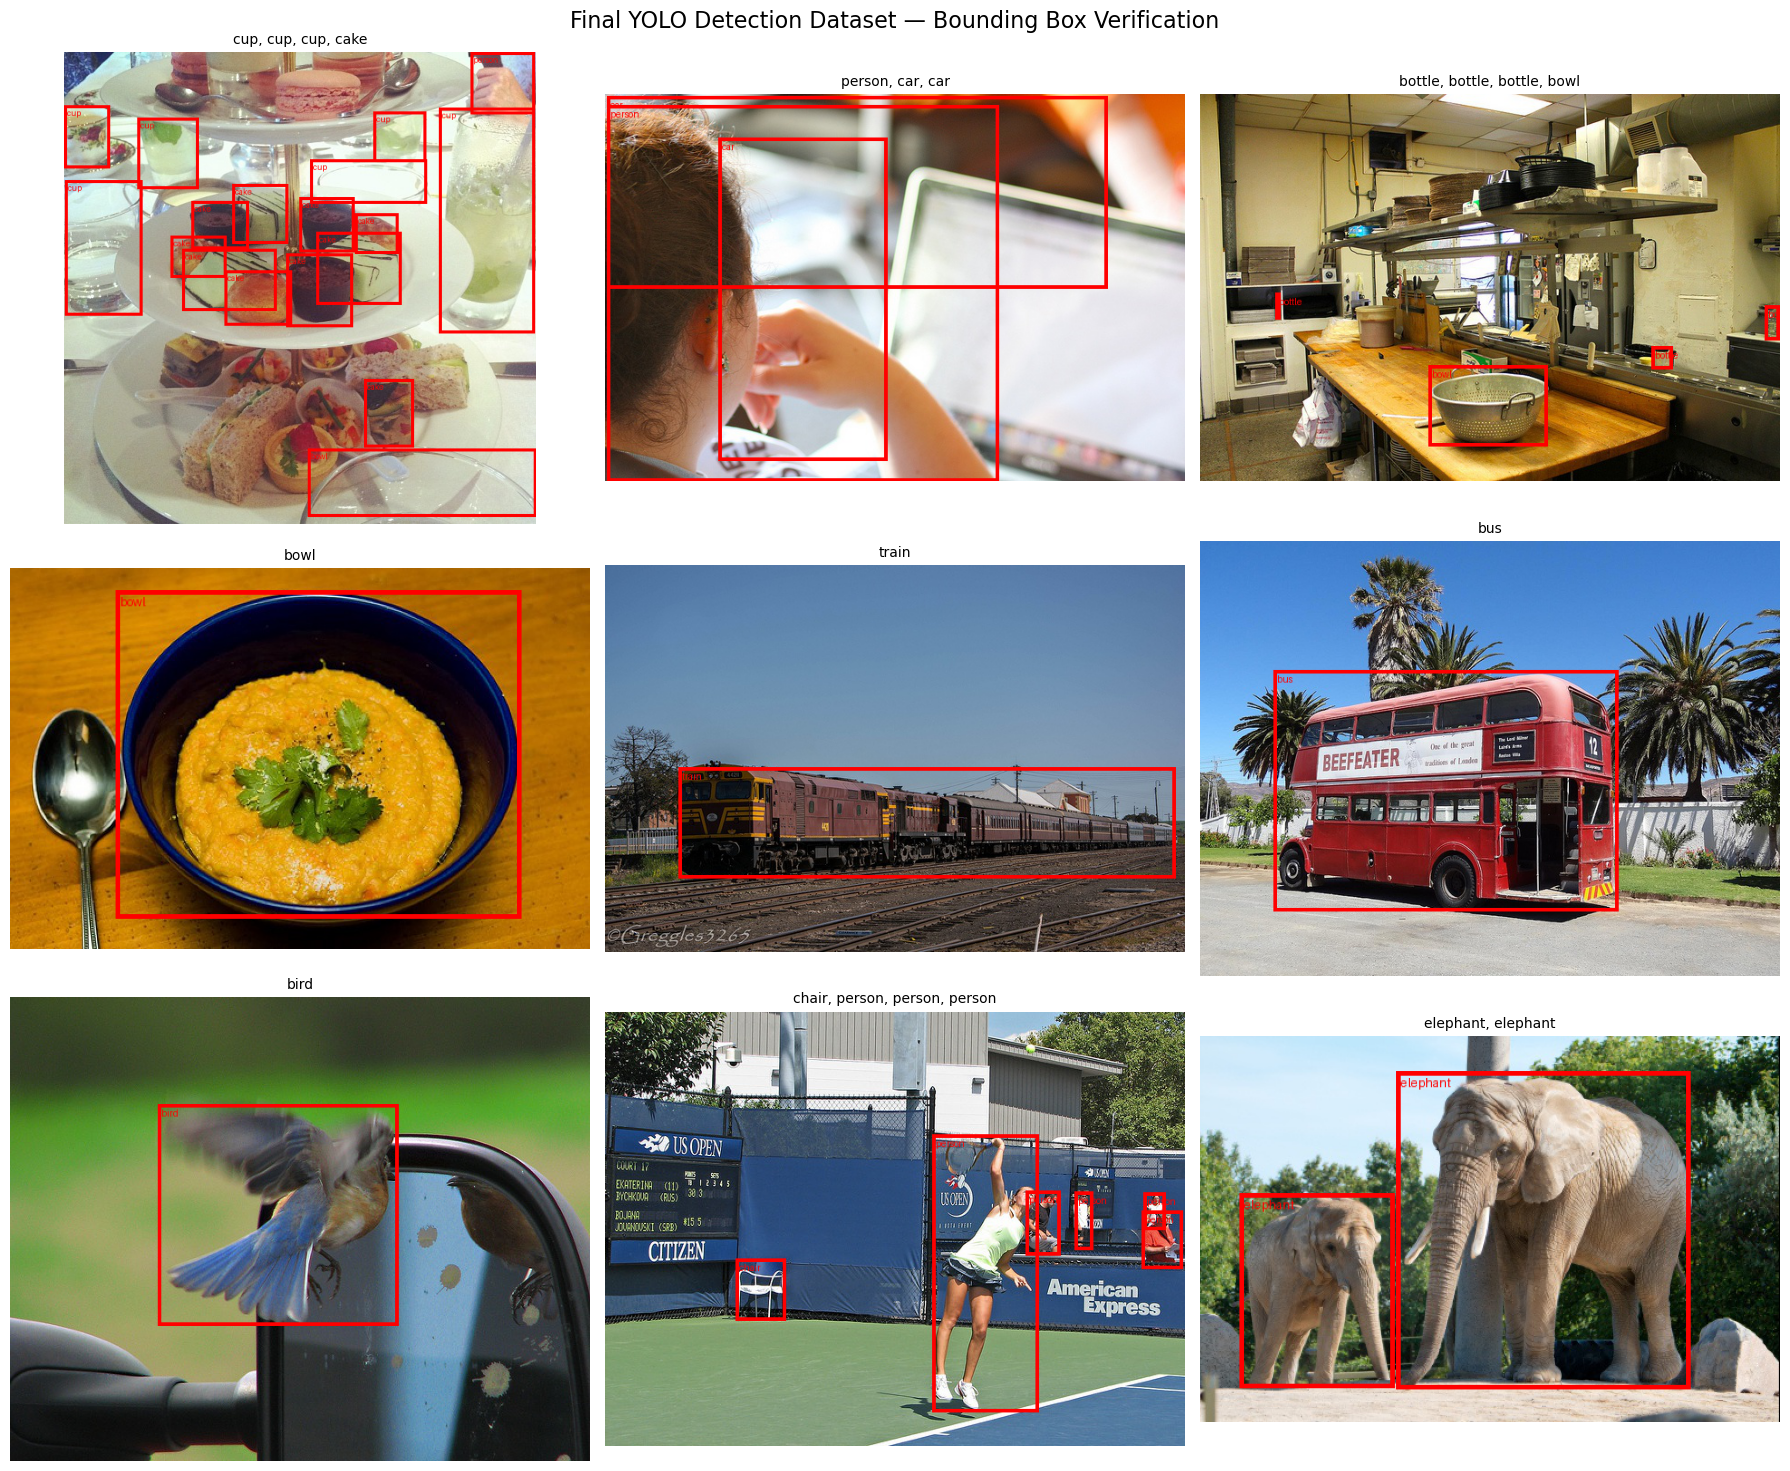

In [15]:
# ============================================================
# CELL 15: VISUALIZE YOLO BOUNDING BOXES
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import random

random.seed(42)

# Choose validation images for visual inspection
val_images = list((IMAGES_DIR / "val").glob("*.jpg"))

sample_images = random.sample(
    val_images,
    min(9, len(val_images))
)

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):

    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    draw = ImageDraw.Draw(image)

    label_path = (
        LABELS_DIR /
        "val" /
        f"{image_path.stem}.txt"
    )

    labels_found = []

    with open(label_path, "r", encoding="utf-8") as f:

        for line in f:

            parts = line.strip().split()

            class_id = int(parts[0])

            x_center = float(parts[1])
            y_center = float(parts[2])
            box_width = float(parts[3])
            box_height = float(parts[4])

            # ----------------------------------------------
            # YOLO normalized -> pixel XYXY
            # ----------------------------------------------

            x1 = int(
                (x_center - box_width / 2) * width
            )

            y1 = int(
                (y_center - box_height / 2) * height
            )

            x2 = int(
                (x_center + box_width / 2) * width
            )

            y2 = int(
                (y_center + box_height / 2) * height
            )

            class_name = yolo_names[class_id]

            labels_found.append(class_name)

            # Bounding box
            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=4
            )

            # Class label
            draw.text(
                (x1 + 4, max(0, y1 + 4)),
                class_name,
                fill="red"
            )

    ax.imshow(image)

    ax.set_title(
        ", ".join(labels_found[:4]),
        fontsize=10
    )

    ax.axis("off")


plt.suptitle(
    "Final YOLO Detection Dataset — Bounding Box Verification",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# CELL 16: CREATE FINAL DATASET METADATA
# ============================================================

import json
from datetime import datetime

METADATA_PATH = BASE_DIR / "dataset_metadata.json"

metadata = {
    "project": "SmartVision AI - Intelligent Multi-Class Object Recognition System",

    "dataset": {
        "source": "COCO",
        "provider": "Hugging Face - detection-datasets/coco",
        "loading_method": "streaming",
        "num_classes": 25,
        "target_images_per_class": 100,
        "class_assignments": 2500
    },

    "selected_classes": list(SELECTED_CLASSES.keys()),

    "classification": {
        "purpose": "Single-object image classification",
        "image_size": [224, 224],
        "image_mode": "RGB",

        "split": {
            "train": 1750,
            "val": 375,
            "test": 375,
            "total": 2500
        },

        "split_ratio": {
            "train": 0.70,
            "val": 0.15,
            "test": 0.15
        },

        "images_per_class": {
            "train": 70,
            "val": 15,
            "test": 15,
            "total": 100
        },

        "unique_source_images": {
            "train": 1410,
            "val": 283,
            "test": 296,
            "total": 1989
        },

        "source_leakage": {
            "train_val": 0,
            "train_test": 0,
            "val_test": 0
        },

        "preprocessing": {
            "crop_source": "COCO bounding boxes",
            "bbox_source_format": "XYXY",
            "resize": "224x224",
            "normalization": "ImageNet mean/std during model loading"
        }
    },

    "detection": {
        "purpose": "Multi-object detection using YOLOv8",

        "class_assignments": {
            "train": 1750,
            "val": 375,
            "test": 375,
            "total": 2500
        },

        "unique_images": {
            "train": 1108,
            "val": 353,
            "test": 356,
            "total": 1817
        },

        "annotated_objects": {
            "train": 7418,
            "val": 1856,
            "test": 1714,
            "total": 10988
        },

        "split_ratio_per_class": {
            "train": 0.70,
            "val": 0.15,
            "test": 0.15
        },

        "images_per_class_assignment": {
            "train": 70,
            "val": 15,
            "test": 15,
            "total": 100
        },

        "annotation_format": "YOLO",

        "bbox_conversion": {
            "source_format": "XYXY",
            "target_format": "normalized YOLO x_center y_center width height"
        },

        "yolo_class_mapping": {
            str(index): name
            for index, name in enumerate(yolo_names)
        },

        "source_leakage": {
            "train_val": 0,
            "train_test": 0,
            "val_test": 0
        },

        "validation": {
            "missing_labels": 0,
            "missing_images": 0,
            "empty_labels": 0,
            "invalid_annotation_lines": 0,
            "bounding_box_visual_check": "passed"
        },

        "config_file": "detection/data.yaml"
    },

    "folder_structure": {
        "classification": {
            "train": "classification/train",
            "val": "classification/val",
            "test": "classification/test"
        },

        "detection": {
            "train_images": "detection/images/train",
            "val_images": "detection/images/val",
            "test_images": "detection/images/test",
            "train_labels": "detection/labels/train",
            "val_labels": "detection/labels/val",
            "test_labels": "detection/labels/test"
        }
    },

    "quality_checks": {
        "classification_file_count": "passed",
        "classification_image_dimensions": "passed",
        "classification_rgb_mode": "passed",
        "classification_source_leakage": "passed",
        "detection_image_label_matching": "passed",
        "detection_annotation_validation": "passed",
        "detection_source_leakage": "passed",
        "detection_bbox_visualization": "passed"
    },

    "created_at": datetime.now().isoformat(timespec="seconds")
}


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )


print("=" * 72)
print("FINAL DATASET METADATA CREATED")
print("=" * 72)

print("Path:")
print(METADATA_PATH)

print("\nSummary:")
print("Classes                    :", metadata["dataset"]["num_classes"])
print("Classification images      :", metadata["classification"]["split"]["total"])
print("Detection unique images    :", metadata["detection"]["unique_images"]["total"])
print("Detection class assignments:", metadata["detection"]["class_assignments"]["total"])
print("Detection objects          :", metadata["detection"]["annotated_objects"]["total"])

print("\nConfiguration:")
print("YOLO config :", metadata["detection"]["config_file"])

print("\nQuality checks:")

for check, status in metadata["quality_checks"].items():
    print(f"{check:40s}: {status}")

print("\n" + "=" * 72)
print("✅ dataset_metadata.json successfully created.")
print("=" * 72)

FINAL DATASET METADATA CREATED
Path:
E:\SmartVision-AI\data\final_dataset\dataset_metadata.json

Summary:
Classes                    : 25
Classification images      : 2500
Detection unique images    : 1817
Detection class assignments: 2500
Detection objects          : 10988

Configuration:
YOLO config : detection/data.yaml

Quality checks:
classification_file_count               : passed
classification_image_dimensions         : passed
classification_rgb_mode                 : passed
classification_source_leakage           : passed
detection_image_label_matching          : passed
detection_annotation_validation         : passed
detection_source_leakage                : passed
detection_bbox_visualization            : passed

✅ dataset_metadata.json successfully created.
